# Mini-RQ 2: Architektur oder Embedding?

**Deep Learning · Master Wirtschaftsinformatik · HHN · WS 2026/27**

| | |
|---|---|
| **Team** | Overfitted (Hamza Tayar (212560), Abdullah Bayram Tayar (212559), Olga Tasmali (229442)) |
| **Abgabe** | So 22.11.2026, 23:55 |
| **Aufgabenstellung** | `RQ2_Architektur_Embedding` (ILIAS) |

---

## Wozu dieses Notebook da ist

Dieses Notebook ist ein **Gerüst, keine Vorlage zum Ausfüllen**. Es enthält nur das, was für alle Teams gleich sein muss, damit die Ergebnisse vergleichbar sind:

1. **Reproduzierbarkeit:** Seeds setzen, Versionen und Gerät ausgeben
2. **Daten:** AG News (Thema) und Rotten Tomatoes (Sentiment) laden und fest aufteilen
3. **Tokenisierung und Vokabular:** damit alle Modelle dieselben Eingaben sehen
4. **Embeddings:** GloVe laden und die drei Varianten (zufällig, GloVe fest, GloVe mittrainiert) bauen
5. **Ergebnisschema:** die Liste, in die jeder Messwert kommt
6. **Teil B:** eine Hilfsfunktion für die Auswahlen von k Seeds
7. **Export** und **Abgabecheckliste**

Alles andere schreibt ihr selbst: die drei Modelle (Baseline, TextCNN, LSTM), die Trainingsschleife, die Metriken, die Heatmaps, die Auswertung von Teil B und die Diskussion.

## 1. Reproduzierbarkeit

Neuronale Netze starten mit zufälligen Gewichten, und auch das Mischen der Batches ist zufällig. Ein **Seed** legt den Zufallsgenerator fest: gleicher Seed, gleiches Ergebnis.

**Ruft `set_seed` am Anfang jedes einzelnen Laufs** mit dem Seed dieses Laufs auf, nicht nur einmal oben im Notebook. Laut Aufgabenstellung braucht Teil A mindestens 3 Seeds je Konfiguration, Teil B mindestens 10 Seeds je Architektur. Die Seeds 1 bis 3 aus Teil A zählen in Teil B mit, benutzt also **dieselben Seed-Nummern 1 bis 10**.

Die Zelle enthält außerdem `count_params`, mit dem ihr die Parameterzahl eurer Modelle für den Bericht bestimmt.

In [33]:
import random
import sys
import time

import numpy as np
import torch
import torch.nn as nn


def set_seed(seed: int) -> None:
    """Fix all random number generators used in this notebook."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def count_params(model: nn.Module, trainable_only: bool = False) -> int:
    """Number of parameters of a model (for the report)."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


# CPU is sufficient for this assignment. A GPU is used automatically if available.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Python : {sys.version.split()[0]}")
print(f"NumPy  : {np.__version__}")
print(f"PyTorch: {torch.__version__}")
print(f"Device : {device}")

Python : 3.12.10
NumPy  : 2.4.1
PyTorch: 2.14.1+cpu
Device : cpu


## 2. Daten

| Aufgabe | Datensatz | Klassen | Zufallsniveau |
|---|---|---|---|
| `thema` | **AG News**: Nachrichtenmeldungen (Titel + Beschreibung), 120 000 Trainings- und 7 600 Testbeispiele | World, Sports, Business, Sci/Tech | 25 % |
| `sentiment` | **Rotten Tomatoes**: Filmkritik-Sätze, mitgelieferte Aufteilung in Train, Validation und Test | negativ, positiv | 50 % |

Die Zelle lädt beide Datensätze über die Bibliothek `datasets` (beim ersten Mal Download in den Hugging-Face-Cache) und erzeugt für jede Aufgabe ein Dictionary mit `train`, `val` und `test`. Jeder Teil ist ein Paar `(Texte, Labels)`.

**Was ihr festlegt:** `N_TRAIN_THEMA` und `N_VAL_THEMA`. AG News ist groß, für das Rechenbudget (unter einer Stunde, ohne GPU) nehmt ihr nur einen Teil. Wählt die Größen einmal, **begründet sie im Bericht und ändert sie danach nicht mehr**. Sie gelten für alle Modelle, Embeddings und Seeds. Der Teilsatz wird mit dem festen `SPLIT_SEED` gezogen und ist damit für alle Teams mit denselben Größen identisch.

**Unsere Wahl: 20.000 Trainings- und 2.000 Validierungstexte.** Der Testteil bleibt der volle offizielle Test mit 7.600 Texten.

- **20.000 Training:** Das LSTM ist unser langsamstes Modell. Mit 20.000 Texten dauert ein Lauf auf der CPU rund eine Minute, alle Läufe zusammen bleiben damit unter einer Stunde (Hochrechnung in A.3). Gleichzeitig sind es pro Klasse rund 5.000 Texte, deutlich mehr als bei Rotten Tomatoes (rund 4.300 pro Klasse).
- **2.000 Validation:** Damit wählen wir Lernrate und Epochenzahl. Bei 2.000 Texten entspricht ein Text 0,05 Prozentpunkten, die Auswahl wird also nicht von einzelnen Texten bestimmt.
- Die Größen gelten für alle Modelle, Embeddings und Seeds und werden danach nicht mehr geändert.

In [34]:
from datasets import load_dataset

SPLIT_SEED = 2026         # fixed for all teams - do not change
N_TRAIN_THEMA = 20_000    # our choice (see the markdown cell above), fixed for all runs
N_VAL_THEMA = 2_000       # our choice (see the markdown cell above), fixed for all runs


def to_pair(split):
    """Hugging Face split -> (list of texts, list of int labels)."""
    return list(split["text"]), list(split["label"])


def subset(pair, n, rng):
    """Random subset of size n of a (texts, labels) pair."""
    idx = rng.permutation(len(pair[0]))[:n]
    return [pair[0][i] for i in idx], [pair[1][i] for i in idx]


# --- Task "thema": AG News (4 classes) ---
ag = load_dataset("fancyzhx/ag_news")   # new HF id, same data as "ag_news"
ag_train_full = to_pair(ag["train"])
ag_test = to_pair(ag["test"])
rng = np.random.RandomState(SPLIT_SEED)
perm = rng.permutation(len(ag_train_full[0]))
val_idx, train_idx = perm[:N_VAL_THEMA], perm[N_VAL_THEMA:N_VAL_THEMA + N_TRAIN_THEMA]
ag_val = ([ag_train_full[0][i] for i in val_idx], [ag_train_full[1][i] for i in val_idx])
ag_train = ([ag_train_full[0][i] for i in train_idx], [ag_train_full[1][i] for i in train_idx])

# --- Task "sentiment": Rotten Tomatoes (2 classes), split as provided ---
rt = load_dataset("cornell-movie-review-data/rotten_tomatoes")   # new HF id, same data as "rotten_tomatoes"

TASKS = {
    "thema": {"train": ag_train, "val": ag_val, "test": ag_test, "n_classes": 4},
    "sentiment": {
        "train": to_pair(rt["train"]),
        "val": to_pair(rt["validation"]),
        "test": to_pair(rt["test"]),
        "n_classes": 2,
    },
}

for name, task in TASKS.items():
    sizes = {part: len(task[part][0]) for part in ("train", "val", "test")}
    print(f"{name:10s} classes={task['n_classes']}  {sizes}")
    print("   example:", task["train"][0][0][:80].replace("\n", " "), "->", task["train"][1][0])

thema      classes=4  {'train': 20000, 'val': 2000, 'test': 7600}
   example: U.S. Air Strike Kills One Iraqi in Falluja (Reuters) Reuters - U.S. warplanes la -> 0
sentiment  classes=2  {'train': 8530, 'val': 1066, 'test': 1066}
   example: the rock is destined to be the 21st century's new " conan " and that he's going  -> 1


## 3. Tokenisierung und Vokabular

Damit alle Modelle dieselben Eingaben sehen, ist die Vorverarbeitung fest: Kleinschreibung, Zerlegung in Wörter und Zahlen, ein Vokabular **nur aus dem Trainingsteil** (Wörter, die mindestens `MIN_FREQ`-mal vorkommen) und Padding bzw. Abschneiden auf `MAX_LEN` Token. Index 0 ist `<PAD>`, Index 1 ist `<UNK>` (Wörter, die nicht im Vokabular stehen).

`MAX_LEN` ist je Aufgabe vorgegeben: AG News hat längere Texte als die Sentiment-Sätze. Die Zelle erzeugt für jede Aufgabe die Tensoren `X_train`, `X_val`, `X_test` (Form `[N, MAX_LEN]`) und `y_train`, `y_val`, `y_test`.

In [35]:
import re
from collections import Counter

PAD, UNK = 0, 1
MIN_FREQ = 2
MAX_LEN = {"thema": 60, "sentiment": 40}   # fixed for all teams - do not change


def tokenize(text: str) -> list:
    return re.findall(r"[a-z0-9']+", text.lower())


def build_vocab(texts, min_freq=MIN_FREQ) -> dict:
    counts = Counter(tok for t in texts for tok in tokenize(t))
    vocab = {"<PAD>": PAD, "<UNK>": UNK}
    for tok, c in counts.most_common():
        if c >= min_freq:
            vocab[tok] = len(vocab)
    return vocab


def encode(texts, vocab, max_len) -> torch.Tensor:
    """List of texts -> LongTensor [N, max_len], padded with 0 and truncated."""
    out = torch.zeros(len(texts), max_len, dtype=torch.long)
    for i, t in enumerate(texts):
        ids = [vocab.get(tok, UNK) for tok in tokenize(t)][:max_len]
        out[i, :len(ids)] = torch.tensor(ids, dtype=torch.long)
    return out


DATA = {}   # task -> dict with vocab, X_*, y_*, n_classes
for name, task in TASKS.items():
    vocab = build_vocab(task["train"][0])
    d = {"vocab": vocab, "n_classes": task["n_classes"]}
    for part in ("train", "val", "test"):
        d[f"X_{part}"] = encode(task[part][0], vocab, MAX_LEN[name])
        d[f"y_{part}"] = torch.tensor(task[part][1], dtype=torch.long)
    DATA[name] = d
    print(f"{name:10s} vocab={len(vocab):,}  X_train={tuple(d['X_train'].shape)}  X_test={tuple(d['X_test'].shape)}")

thema      vocab=21,700  X_train=(20000, 60)  X_test=(7600, 60)
sentiment  vocab=8,971  X_train=(8530, 40)  X_test=(1066, 40)


## 4. Embeddings

Alle drei Varianten haben **50 Dimensionen**, damit sich nur die Herkunft der Vektoren unterscheidet:

| Variante | `variante` | Startwerte | wird mit dem Modell trainiert? |
|---|---|---|---|
| zufällig | `"zufaellig"` | zufällig | ja |
| GloVe fest | `"glove_fest"` | GloVe | nein (eingefroren) |
| GloVe mittrainiert | `"glove_mittrainiert"` | GloVe | ja |

Die Funktion `make_embedding(variante, vocab, glove_matrix)` gibt eine fertige `nn.Embedding`-Schicht zurück. Ihr baut sie **in jedem Modell an der Stelle ein, an der sonst `nn.Embedding` stünde**. `padding_idx=0` sorgt dafür, dass der Vektor für `<PAD>` null bleibt und keinen Gradienten bekommt.

Wörter, die im Vokabular, aber nicht in GloVe stehen, bekommen einen kleinen zufälligen Vektor (gleiche Streuung wie GloVe). Die Zelle gibt aus, wie viel Prozent des Vokabulars GloVe abdeckt. Diese Zahl gehört in den Bericht, weil sie zwischen den beiden Aufgaben stark abweichen kann.

**Hinweis zum Laden von GloVe.** Die Vorlage lädt GloVe mit `gensim`. Unter Python 3.14 lässt sich `gensim` (noch) nicht installieren. Die Zelle nutzt deshalb `gensim`, wenn es vorhanden ist, und lädt sonst **genau dieselbe Datei** (`glove-wiki-gigaword-50`, ca. 66 MB), die auch `gensim` herunterlädt, direkt aus dem offiziellen gensim-data-Archiv auf GitHub in den Ordner `data/`. Die Vektoren sind identisch, alle festen Werte (50 Dimensionen, `SPLIT_SEED`, Matrix-Aufbau) bleiben unverändert.

In [36]:
import gzip
import os
import urllib.request

EMB_DIM = 50
GLOVE_URL = ("https://github.com/RaRe-Technologies/gensim-data/releases/download/"
             "glove-wiki-gigaword-50/glove-wiki-gigaword-50.gz")
GLOVE_FILE = os.path.join("data", "glove-wiki-gigaword-50.gz")


class GloveVectors:
    """Minimal replacement for the gensim object: same file, same interface as used below."""

    def __init__(self, path):
        self.index_to_key, vectors = [], []
        with gzip.open(path, "rt", encoding="utf-8") as f:
            next(f)                                   # header line: "400000 50"
            for line in f:
                parts = line.rstrip().split(" ")
                self.index_to_key.append(parts[0])
                vectors.append(np.asarray(parts[1:], dtype=np.float32))
        self.vectors = np.stack(vectors)
        self.vector_size = self.vectors.shape[1]
        self.key_to_index = {word: i for i, word in enumerate(self.index_to_key)}

    def __getitem__(self, word):
        return self.vectors[self.key_to_index[word]]


try:
    import gensim.downloader as api
    glove = api.load("glove-wiki-gigaword-50")   # first call downloads ca. 70 MB
except ImportError:
    # gensim cannot be installed on Python 3.14: load the identical file directly
    os.makedirs("data", exist_ok=True)
    if not os.path.exists(GLOVE_FILE):
        print("Lade GloVe herunter (ca. 66 MB) ...")
        urllib.request.urlretrieve(GLOVE_URL, GLOVE_FILE)
    glove = GloveVectors(GLOVE_FILE)
assert glove.vector_size == EMB_DIM
GLOVE_STD = float(np.std(glove.vectors))


def build_glove_matrix(vocab: dict, seed: int = SPLIT_SEED) -> torch.Tensor:
    """Matrix [len(vocab), 50]: GloVe vector if known, small random vector otherwise, zeros for <PAD>."""
    g = torch.Generator().manual_seed(seed)
    matrix = torch.randn(len(vocab), EMB_DIM, generator=g) * GLOVE_STD
    for tok, idx in vocab.items():
        if tok in glove.key_to_index:
            matrix[idx] = torch.tensor(glove[tok])
    matrix[PAD] = 0.0
    return matrix


def make_embedding(variante: str, vocab: dict, glove_matrix: torch.Tensor) -> nn.Embedding:
    """Embedding layer for one of the three variants. Call set_seed(seed) BEFORE this for "zufaellig"."""
    if variante == "zufaellig":
        emb = nn.Embedding(len(vocab), EMB_DIM, padding_idx=PAD)
    elif variante == "glove_fest":
        emb = nn.Embedding.from_pretrained(glove_matrix.clone(), freeze=True, padding_idx=PAD)
    elif variante == "glove_mittrainiert":
        emb = nn.Embedding.from_pretrained(glove_matrix.clone(), freeze=False, padding_idx=PAD)
    else:
        raise ValueError(f"unknown variant: {variante}")
    return emb


GLOVE_MATRIX = {}
for name, d in DATA.items():
    GLOVE_MATRIX[name] = build_glove_matrix(d["vocab"])
    covered = sum(tok in glove.key_to_index for tok in d["vocab"]) / len(d["vocab"])
    print(f"{name:10s} GloVe covers {covered:.1%} of the vocabulary")

thema      GloVe covers 95.6% of the vocabulary
sentiment  GloVe covers 95.8% of the vocabulary


## 5. Ergebnisschema

Jeder einzelne Messwert wird als **eine Zeile** in der Liste `results` abgelegt, als Dictionary mit genau diesen sieben Spalten:

| Spalte | Bedeutung | Beispiel |
|---|---|---|
| `run_id` | eindeutige Kennung des Laufs | `"thema-lstm-glovefest_s1"` |
| `konfiguration` | Aufgabe, Modell und Embedding | `"aufgabe=thema \| modell=lstm \| embedding=glove_fest"` |
| `seed` | verwendeter Seed (1 bis 10 in Teil B) | `1` |
| `split` | auf welchem Teil gemessen | `"test"` oder `"val"` |
| `metrik` | Name der Metrik | `"accuracy"`, `"macro_f1"` |
| `wert` | Messwert | `0.874` |
| `laufzeit_s` | Trainingszeit des Laufs in Sekunden | `23.4` |

Ein Lauf mit zwei Metriken auf dem Testset ergibt also zwei Zeilen mit derselben `run_id`. Zusätzliche Spalten bitte nicht anlegen. Wenn ihr mehr festhalten wollt, gehört es in die `konfiguration`.

`add_result` hängt eine Zeile an und prüft dabei das Schema. Die Zeilen aus **Teil B** (Auswahlen von k Seeds) gehören **nicht** in `results`, sie sind eine Auswertung der Läufe und kein eigener Lauf.

In [37]:
RESULT_COLUMNS = ["run_id", "konfiguration", "seed", "split", "metrik", "wert", "laufzeit_s"]

results = []   # one dict per measured value, keys = RESULT_COLUMNS


def add_result(run_id, konfiguration, seed, split, metrik, wert, laufzeit_s):
    """Append one measured value in the required schema."""
    if split not in ("test", "val"):
        raise ValueError("split must be 'test' or 'val'")
    results.append({
        "run_id": run_id, "konfiguration": konfiguration, "seed": int(seed),
        "split": split, "metrik": metrik, "wert": float(wert), "laufzeit_s": float(laufzeit_s),
    })


# Example of one call (delete or ignore): two rows for one run
# add_result("thema-lstm-glovefest_s1", "aufgabe=thema | modell=lstm | embedding=glove_fest", 1, "test", "accuracy", 0.874, 23.4)

## 6. Teil B: Auswahlen von k Seeds

Für Teil B habt ihr pro Architektur **10 Test-Accuracies** (Seeds 1 bis 10). Die Funktion `subset_means(values, k)` gibt die Mittelwerte **aller möglichen Auswahlen** von k dieser Werte zurück: bei 10 Werten sind das 10, 45, 120, 210, 252, 210, 120, 45 und 10 Mittelwerte für k = 1 bis 9. Ein Wert zählt in einer Auswahl höchstens einmal, und es braucht keinen Zufall.

Daraus bildet ihr selbst, je k und Modell, den Durchschnitt und das Band (5. bis 95. Perzentil), und zeichnet beides gegen k. Das Beispiel unten benutzt **erfundene** Zahlen und dient nur dazu, die Funktion auszuprobieren.

In [38]:
from itertools import combinations


def subset_means(values, k: int) -> np.ndarray:
    """Means of all possible selections of k values out of `values` (without replacement)."""
    return np.array([np.mean(c) for c in combinations(values, k)])


# Demo with INVENTED numbers - replace by your own 10 test accuracies per architecture
demo = [80, 82, 79, 83, 81, 80, 82, 78, 81, 80]
for k in (1, 3, 5):
    m = subset_means(demo, k)
    print(f"k={k}: {len(m):3d} selections, mean={m.mean():.1f}, 5-95% band=({np.percentile(m, 5):.1f}, {np.percentile(m, 95):.1f})")

k=1:  10 selections, mean=80.6, 5-95% band=(78.5, 82.5)
k=3: 120 selections, mean=80.6, 5-95% band=(79.3, 81.7)
k=5: 252 selections, mean=80.6, 5-95% band=(79.8, 81.4)


---

## Ab hier: eure Experimente

Hier beginnt eure Arbeit. Gliedert sie so, dass jemand ohne Vorwissen folgen kann. Kurze Markdown-Zellen, die sagen, was als Nächstes passiert und warum, sind Teil der Bewertung („Dokumentation und Lesbarkeit“).

Ein sinnvoller Ablauf:

1. **Erwartung** in einer Markdown-Zelle festhalten, bevor ihr den ersten Lauf startet
2. die drei **Modelle** definieren (Baseline, TextCNN, LSTM), jeweils mit `make_embedding` als Embedding-Schicht
3. eine **Funktion für einen Lauf**: `set_seed`, Modell bauen, trainieren, auf Validation und Test messen, Zeit stoppen, `add_result` aufrufen
4. erst **ein** Lauf zum Testen, dann die Schleife über Aufgaben, Architekturen, Embeddings und Seeds (Teil A)
5. Teil B: die Heatmap-Spalte (Aufgabe und Embedding) wählen, in der die beiden besten Architekturen am dichtesten beieinander liegen, und dort die Seeds 4 bis 10 nachlegen
6. Heatmaps, Teil-B-Abbildung und Diskussion

Rechnet die Laufzeit vorab hoch: Ein Lauf auf einer Stichprobe zeigt, wie viele von den mindestens 75 Läufen in die Stunde passen. Passt es nicht, verkleinert ihr `N_TRAIN_THEMA`, die Epochenzahl oder die Modellgröße, **nie** die Zahl der Seeds.

---

# Teil A: Architektur × Embedding

Ab hier beginnt unsere Arbeit. Der Ablauf:

| Abschnitt | Was passiert |
|---|---|
| A.1 | Erwartung vor dem ersten Lauf |
| A.2 | Die drei Modelle und ihre Parameterzahl |
| A.3 | Ein Lauf: trainieren, auf Validation abbrechen, auf Test messen, Hochrechnung der Laufzeit |
| A.4 | Lernrate auf Validation wählen |
| A.5 | Alle 18 Konfigurationen mit je 3 Seeds |
| A.6 | Ergebnistabelle |
| A.7 | Die beiden Heatmaps |
| A.8 | Spannweiten: Bewegt die Architektur oder das Embedding mehr? |

Teil B, der Zusatzbefund und das Fazit folgen danach.

## A.1 Unsere Erwartung (vor dem ersten Lauf)

Die Aufgabenstellung verlangt, die Erwartung **vor** dem ersten Lauf festzuhalten. Wir stützen sie auf das, was wir in den Wochen 3 bis 5 gesehen haben.

**Thema (AG News):**
- Das Thema einer Nachricht hängt vor allem an einzelnen Schlüsselwörtern („election“, „goal“, „shares“, „software“). Die Reihenfolge der Wörter ist kaum nötig. In der Übung aus Woche 5 hielt die Mean-Pooling-Baseline auf AG News mit RNN, LSTM und GRU mit.
- Wir erwarten deshalb **kleine Unterschiede zwischen den Architekturen**, alle deutlich über dem Zufallsniveau von 25 %.
- Beim Embedding erwarten wir, dass **GloVe hilft**, weil GloVe auf Wikipedia und Nachrichten trainiert wurde, also auf sehr ähnlichen Texten.

**Sentiment (Rotten Tomatoes):**
- Hier zählt die Reihenfolge mehr: Verneinungen („not funny“) und Wendungen („but“) drehen die Aussage. Wir erwarten, dass **TextCNN und LSTM vor der Baseline** liegen, das LSTM vielleicht knapp vorne.
- Beim Embedding erwarten wir **„GloVe mittrainiert“ vorne**: GloVe bringt Wissen über Wörter mit, kennt aber kein Sentiment (in GloVe liegen „good“ und „bad“ nah beieinander, weil sie in ähnlichen Kontexten stehen). Das Weitertrainieren kann das korrigieren. **„GloVe fest“** könnte hier schwächer sein.

**Was bewegt mehr?** Wir erwarten, dass das **Embedding** die Accuracy stärker bewegt als die Architektur, vor allem bei Sentiment mit wenig Trainingsdaten.

**Stabilität der Rangfolge:** Bei Thema erwarten wir sehr knappe Abstände zwischen den Architekturen. Dort dürfte die Rangfolge mit 3 Seeds **nicht** belastbar sein.

## A.2 Die drei Modelle

Alle drei Modelle bekommen ihre Embedding-Schicht von `make_embedding` (Abschnitt 4), sonst unterscheiden sie sich nur im Mittelteil. Die Bausteine stammen aus den Übungen:

| Modell | Aufbau | Woher |
|---|---|---|
| **Baseline** | Embedding → Mean Pooling mit Maske → Linear → ReLU → Dropout → Linear | `MeanPoolBaseline`, Woche 3 und Woche 5 (Aufgabe 8) |
| **TextCNN** | Embedding → Filter über 2, 3 und 4 Wörter (je 32 Filter) → ReLU → Global Max Pooling → Dropout → Linear | `TicketTextCNN`, Woche 4 (Aufgabe 5b) |
| **LSTM** | Embedding → LSTM (Gedächtnis 48) → letzter Hidden State → Dropout → Linear | `TextLSTM`, Woche 5 (Aufgabe 5) |

**Warum diese Größen?** Die Aufgabe verlangt eine vergleichbare Größenordnung. Wir haben die Modelle so eingestellt, dass auch der Teil **nach** dem Embedding etwa gleich groß ist (rund 13.000 bis 20.000 Parameter). Den größten Teil aller Parameter macht ohnehin die Embedding-Tabelle aus (Vokabular × 50), und die ist bei allen drei Modellen gleich groß.

**Eine Besonderheit beim LSTM: das Padding.** Die Vorlage füllt kürzere Texte **hinten** mit `<PAD>` auf (fest für alle Teams). Aus Woche 5 kennen wir die **Padding-Falle**: Liest ein LSTM die Nullen hinten mit, muss sein Gedächtnis viele leere Schritte überstehen, bevor wir den letzten Hidden State abgreifen. Wir lösen das mit `pack_padded_sequence`: Das LSTM bekommt die echte Länge jedes Textes und hört nach dem letzten echten Wort auf. `h_n[-1]` ist dann das Gedächtnis **nach dem letzten echten Wort**, egal wie viel Padding folgt.

**TextCNN und Padding:** Wie in Woche 4 maskieren wir das Padding beim TextCNN nicht. Die `<PAD>`-Zeile im Embedding ist ein Nullvektor, das Global Max Pooling nimmt ohnehin den stärksten Treffer im Text.

In [39]:
import torch.nn.functional as F
import pandas as pd


class MeanPoolBaseline(nn.Module):
    """Week 3 / week 5: average of all word vectors (padding ignored), then a small MLP. No word order."""

    def __init__(self, embedding, n_classes, hidden_dim=256, dropout=0.3):
        super().__init__()
        self.embedding = embedding
        self.mlp = nn.Sequential(
            nn.Linear(embedding.embedding_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, n_classes),
        )

    def forward(self, x):                                   # x: (texts, words) of word IDs
        mask = (x != PAD).float().unsqueeze(2)              # 1 for real words, 0 for padding
        mean = (self.embedding(x) * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        return self.mlp(mean)


class TextCNN(nn.Module):
    """Week 4: filters over 2, 3 and 4 words, global max pooling per filter."""

    def __init__(self, embedding, n_classes, n_filters=32, kernel_sizes=(2, 3, 4), dropout=0.3):
        super().__init__()
        self.embedding = embedding
        self.convs = nn.ModuleList([
            nn.Conv1d(in_channels=embedding.embedding_dim, out_channels=n_filters, kernel_size=k)
            for k in kernel_sizes
        ])
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(n_filters * len(kernel_sizes), n_classes)

    def forward(self, x):
        embedded = self.embedding(x).transpose(1, 2)        # Conv1d wants (texts, dimensions, words)
        pooled = [F.relu(conv(embedded)).max(dim=2).values for conv in self.convs]   # global max pooling
        return self.fc(self.dropout(torch.cat(pooled, dim=1)))


class TextLSTM(nn.Module):
    """Week 5: LSTM, the hidden state after the last REAL word summarises the text."""

    def __init__(self, embedding, n_classes, hidden_dim=48, dropout=0.3):
        super().__init__()
        self.embedding = embedding
        self.lstm = nn.LSTM(embedding.embedding_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, n_classes)

    def forward(self, x):
        lengths = (x != PAD).sum(dim=1).clamp(min=1).cpu()  # true length of every text
        packed = nn.utils.rnn.pack_padded_sequence(
            self.embedding(x), lengths, batch_first=True, enforce_sorted=False
        )                                                    # the LSTM stops after the last real word
        output, (h_n, c_n) = self.lstm(packed)
        return self.fc(self.dropout(h_n[-1]))


ARCHITECTURES = {"baseline": MeanPoolBaseline, "textcnn": TextCNN, "lstm": TextLSTM}
EMBEDDINGS = ["zufaellig", "glove_fest", "glove_mittrainiert"]

ARCH_LABELS = {"baseline": "Baseline", "textcnn": "TextCNN", "lstm": "LSTM"}
EMB_LABELS = {"zufaellig": "zufällig", "glove_fest": "GloVe fest", "glove_mittrainiert": "GloVe mittrainiert"}
TASK_LABELS = {"thema": "Thema (AG News)", "sentiment": "Sentiment (Rotten Tomatoes)"}


def build_model(arch, task, variante):
    """Build one model with the embedding layer from section 4."""
    d = DATA[task]
    embedding = make_embedding(variante, d["vocab"], GLOVE_MATRIX[task])
    return ARCHITECTURES[arch](embedding, d["n_classes"])


# Parameter count of every architecture (for the report)
param_rows = []
for task in DATA:
    for arch in ARCHITECTURES:
        set_seed(0)
        model = build_model(arch, task, "zufaellig")
        n_embedding = model.embedding.weight.numel()
        n_all = count_params(model)
        set_seed(0)
        n_trainable_fixed = count_params(build_model(arch, task, "glove_fest"), trainable_only=True)
        param_rows.append({
            "Aufgabe": task,
            "Modell": ARCH_LABELS[arch],
            "Parameter gesamt": f"{n_all:,}".replace(",", "."),
            "davon Embedding": f"{n_embedding:,}".replace(",", "."),
            "ohne Embedding": f"{n_all - n_embedding:,}".replace(",", "."),
            "trainierbar bei GloVe fest": f"{n_trainable_fixed:,}".replace(",", "."),
        })

param_table = pd.DataFrame(param_rows)
display(param_table)

,Aufgabe,Modell,Parameter gesamt,davon Embedding,ohne Embedding,trainierbar bei GloVe fest
0,thema,Baseline,1.099.084,1.085.000,14.084,14.084
1,thema,TextCNN,1.099.884,1.085.000,14.884,14.884
2,thema,LSTM,1.104.396,1.085.000,19.396,19.396
3,sentiment,Baseline,462.120,448.550,13.570,13.570
4,sentiment,TextCNN,463.240,448.550,14.690,14.690
5,sentiment,LSTM,467.848,448.550,19.298,19.298


**So liest man die Tabelle:** „Parameter gesamt“ ist bei allen drei Modellen fast gleich groß, weil die Embedding-Tabelle den Löwenanteil ausmacht. „Ohne Embedding“ zeigt, wie groß der eigentliche Architekturteil ist. Bei „GloVe fest“ ist die Embedding-Tabelle eingefroren, deshalb werden dort nur noch die Parameter ohne Embedding trainiert.

## A.3 Ein Lauf: trainieren, abbrechen, messen

Die Trainingsschleife ist die aus den Übungen (Woche 2 bis 5): Mini-Batches, Adam, Cross-Entropy. Neu ist nur das **Abbruchkriterium auf Validation** (Early Stopping aus Woche 2):

1. Nach jeder Epoche messen wir die Accuracy auf **Validation**.
2. Wird sie zwei Epochen hintereinander nicht besser (`patience = 2`), hören wir auf. Höchstens laufen 10 Epochen.
3. Am Ende laden wir die Gewichte der **besten Epoche auf Validation** zurück.

So wählt jedes Modell seine Epochenzahl selbst, aber nach derselben Regel und **nie anhand des Testsets**. Danach messen wir einmal auf Test.

`run_once` macht einen kompletten Lauf: Seed setzen, Modell bauen, trainieren (Zeit stoppen), auf Validation und Test messen und alles mit `add_result` ins Ergebnisschema schreiben.

**Gemessen werden:** Accuracy und Macro-F1 (`f1_score` aus scikit-learn, wie in RQ1) auf Test und zusätzlich auf Validation (`split = "val"`), dazu die Trainingszeit in Sekunden.

In [40]:
from sklearn.metrics import f1_score

MAX_EPOCHS = 10       # upper limit, the same for every run
PATIENCE = 2          # stop after 2 epochs without improvement on validation
BATCH_SIZE = 64       # as in the exercises of weeks 4 and 5

run_info = []         # extra information per run (epochs etc.), not part of the result schema


def predict(model, X, batch_size=1000):
    """Predicted class for every text."""
    model.eval()
    with torch.no_grad():
        return torch.cat([model(X[i:i + batch_size]).argmax(dim=1) for i in range(0, len(X), batch_size)])


def evaluate(model, X, y):
    """Accuracy and macro-F1."""
    pred = predict(model, X)
    accuracy = (pred == y).float().mean().item()
    macro_f1 = f1_score(y.numpy(), pred.numpy(), average="macro")
    return accuracy, macro_f1


def train_model(model, d, lr):
    """Mini-batch training with Adam and cross-entropy, early stopping on validation accuracy."""
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable, lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    X, y = d["X_train"], d["y_train"]

    best_val, best_epoch, best_state, epochs_without_improvement = -1.0, 0, None, 0
    for epoch in range(MAX_EPOCHS):
        model.train()
        order = torch.randperm(len(X))
        for start in range(0, len(X), BATCH_SIZE):
            idx = order[start:start + BATCH_SIZE]
            optimizer.zero_grad()
            loss = loss_fn(model(X[idx]), y[idx])
            loss.backward()
            optimizer.step()

        val_accuracy, _ = evaluate(model, d["X_val"], d["y_val"])
        if val_accuracy > best_val:
            best_val, best_epoch, epochs_without_improvement = val_accuracy, epoch + 1, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                break

    model.load_state_dict(best_state)          # weights of the best epoch on validation
    return best_epoch


def run_once(task, arch, variante, seed, lr, record=True):
    """One complete run. Returns a dict with all measurements."""
    set_seed(seed)                              # at the start of EVERY run
    model = build_model(arch, task, variante)
    d = DATA[task]

    start = time.time()
    best_epoch = train_model(model, d, lr)
    seconds = time.time() - start

    val_acc, val_f1 = evaluate(model, d["X_val"], d["y_val"])
    test_acc, test_f1 = evaluate(model, d["X_test"], d["y_test"])

    if record:
        run_id = f"{task}-{arch}-{variante.replace('_', '')}_s{seed}"
        konfiguration = f"aufgabe={task} | modell={arch} | embedding={variante}"
        for split, metrik, wert in [("test", "accuracy", test_acc), ("test", "macro_f1", test_f1),
                                    ("val", "accuracy", val_acc), ("val", "macro_f1", val_f1)]:
            add_result(run_id, konfiguration, seed, split, metrik, wert, seconds)
        run_info.append({"task": task, "arch": arch, "variante": variante, "seed": seed,
                         "epochs": best_epoch, "seconds": seconds})

    return {"val_acc": val_acc, "test_acc": test_acc, "test_f1": test_f1,
            "epochs": best_epoch, "seconds": seconds}


# Test run: one run per architecture on both tasks (seed 0, NOT recorded), to estimate the runtime
TEST_LR = 3e-3
seconds_per_run = {}
for task in DATA:
    for arch in ARCHITECTURES:
        r = run_once(task, arch, "zufaellig", seed=0, lr=TEST_LR, record=False)
        seconds_per_run[(task, arch)] = r["seconds"]
        print(f"{task:10s} {ARCH_LABELS[arch]:9s} {r['seconds']:5.1f} s   Epochen {r['epochs']:2d}   "
              f"Validation {r['val_acc']:.1%}")

# Projection: Teil A (3 embeddings x 3 seeds) + Teil B (worst case: 7 more seeds in the slowest column)
per_seed = {task: sum(seconds_per_run[(task, a)] for a in ARCHITECTURES) for task in DATA}
part_a = sum(3 * 3 * per_seed[task] for task in DATA)
part_b_worst = 7 * max(per_seed.values())
tuning = 2 * sum(per_seed.values())
print(f"\nHochrechnung: Lernratenwahl {tuning / 60:.0f} min + Teil A {part_a / 60:.0f} min "
      f"+ Teil B höchstens {part_b_worst / 60:.0f} min = höchstens {(tuning + part_a + part_b_worst) / 60:.0f} min")

thema      Baseline    5.6 s   Epochen  5   Validation 86.7%
thema      TextCNN    10.5 s   Epochen  3   Validation 86.2%
thema      LSTM       41.6 s   Epochen  3   Validation 85.4%
sentiment  Baseline    1.3 s   Epochen  4   Validation 73.9%
sentiment  TextCNN     6.3 s   Epochen  9   Validation 75.6%
sentiment  LSTM       16.6 s   Epochen  6   Validation 74.1%

Hochrechnung: Lernratenwahl 3 min + Teil A 12 min + Teil B höchstens 7 min = höchstens 22 min


**So liest man die Hochrechnung:** Sie rechnet die gemessene Zeit je Lauf auf alle geplanten Läufe hoch. Für Teil B nimmt sie den ungünstigsten Fall an (die langsamste Aufgabe). Liegt die Summe unter 60 Minuten, passt der Versuchsplan ins Rechenbudget. Die Testläufe nutzen Seed 0 und werden **nicht** gespeichert.

## A.4 Lernrate auf Validation wählen

Die Aufgabe verlangt: Hyperparameter **auf Validation** wählen, nie auf dem Testset, und pro Architektur **dieselben Werte** für alle Embeddings und Aufgaben.

Die meisten Werte übernehmen wir aus den Übungen (Batchgröße 64, Dropout 0,3, Adam). Die Epochenzahl wählt das Early Stopping aus A.3 auf Validation. Offen ist die **Lernrate**. In den Übungen kamen 0,001 bis 0,01 vor. Wir probieren **0,001 und 0,003** aus:

- für jede Architektur auf **beiden Aufgaben**,
- mit dem Embedding **„zufällig“**, weil dort am meisten Parameter trainiert werden,
- mit **Seed 0**, der in Teil A und B nicht vorkommt. So bleibt die Wahl unabhängig von den eigentlichen Läufen.

Gewählt wird je Architektur die Lernrate mit der höheren **mittleren Validation-Accuracy über beide Aufgaben**. Diese Läufe kommen nicht ins Ergebnisschema, weil sie nur der Auswahl dienen.

In [41]:
LR_CANDIDATES = [1e-3, 3e-3]
TUNING_SEED = 0

tuning_rows = []
for arch in ARCHITECTURES:
    for lr in LR_CANDIDATES:
        row = {"Modell": ARCH_LABELS[arch], "Lernrate": lr}
        for task in DATA:
            r = run_once(task, arch, "zufaellig", seed=TUNING_SEED, lr=lr, record=False)
            row[f"Validation {task}"] = r["val_acc"]
        row["Mittel"] = np.mean([row[f"Validation {task}"] for task in DATA])
        tuning_rows.append(row)

tuning_table = pd.DataFrame(tuning_rows)

# Choice per architecture: the learning rate with the higher mean validation accuracy
LR = {}
for arch in ARCHITECTURES:
    rows = tuning_table[tuning_table["Modell"] == ARCH_LABELS[arch]]
    LR[arch] = float(rows.loc[rows["Mittel"].idxmax(), "Lernrate"])

display(tuning_table.style.format({c: "{:.1%}" for c in tuning_table.columns if c.startswith("Validation") or c == "Mittel"}))
print("Gewählte Lernrate je Architektur:", {ARCH_LABELS[a]: lr for a, lr in LR.items()})

,Modell,Lernrate,Validation thema,Validation sentiment,Mittel
0,Baseline,0.001000,86.3%,73.5%,79.9%
1,Baseline,0.003000,86.7%,73.9%,80.3%
2,TextCNN,0.001000,85.3%,70.4%,77.8%
3,TextCNN,0.003000,86.2%,75.6%,80.9%
4,LSTM,0.001000,84.3%,70.1%,77.2%
5,LSTM,0.003000,85.4%,74.1%,79.8%


Gewählte Lernrate je Architektur: {'Baseline': 0.003, 'TextCNN': 0.003, 'LSTM': 0.003}


## A.5 Alle 18 Konfigurationen mit je 3 Seeds

3 Architekturen × 3 Embeddings × 2 Aufgaben = **18 Konfigurationen**, jede mit den Seeds **1, 2 und 3**, also **54 Läufe**. Jede Architektur nutzt ihre Lernrate aus A.4, sonst ist alles gleich. Die Seeds 1 bis 3 zählen in Teil B mit.

Die Zelle gibt nach jeder Konfiguration eine Zeile aus.

In [42]:
SEEDS_A = [1, 2, 3]

start_a = time.time()
for task in DATA:
    for arch in ARCHITECTURES:
        for variante in EMBEDDINGS:
            accs = [run_once(task, arch, variante, seed, LR[arch])["test_acc"] for seed in SEEDS_A]
            print(f"{task:10s} {ARCH_LABELS[arch]:9s} {EMB_LABELS[variante]:19s} "
                  f"Test-Accuracy je Seed: {[f'{a:.1%}' for a in accs]}")
print(f"\nTeil A fertig: {len(SEEDS_A) * 18} Läufe in {(time.time() - start_a) / 60:.1f} Minuten")

thema      Baseline  zufällig            Test-Accuracy je Seed: ['87.7%', '87.3%', '87.7%']
thema      Baseline  GloVe fest          Test-Accuracy je Seed: ['87.9%', '88.2%', '87.9%']
thema      Baseline  GloVe mittrainiert  Test-Accuracy je Seed: ['90.6%', '90.5%', '89.6%']
thema      TextCNN   zufällig            Test-Accuracy je Seed: ['87.5%', '87.6%', '87.3%']
thema      TextCNN   GloVe fest          Test-Accuracy je Seed: ['89.5%', '89.4%', '89.7%']
thema      TextCNN   GloVe mittrainiert  Test-Accuracy je Seed: ['90.5%', '90.6%', '90.3%']
thema      LSTM      zufällig            Test-Accuracy je Seed: ['86.3%', '85.8%', '86.5%']
thema      LSTM      GloVe fest          Test-Accuracy je Seed: ['89.1%', '89.3%', '89.9%']
thema      LSTM      GloVe mittrainiert  Test-Accuracy je Seed: ['89.9%', '90.5%', '89.7%']
sentiment  Baseline  zufällig            Test-Accuracy je Seed: ['75.6%', '75.0%', '73.9%']
sentiment  Baseline  GloVe fest          Test-Accuracy je Seed: ['67.7%', '66.3%

## A.6 Ergebnistabelle

Für jede Konfiguration fassen wir die Seeds zusammen: **Mittelwert ± Standardabweichung** von Accuracy und Macro-F1 auf dem Testset, dazu die mittlere Laufzeit und die mittlere Epochenzahl, bei der das Early Stopping die besten Gewichte gefunden hat.

Die Tabelle wird aus `results` gebaut, also genau aus den Zeilen, die später in der CSV stehen.

In [43]:
def results_frame():
    """The result list as a table with separate columns for task, model and embedding."""
    df = pd.DataFrame(results)
    parts = df["konfiguration"].str.extract(r"aufgabe=(\w+) \| modell=(\w+) \| embedding=(\w+)")
    df["task"], df["arch"], df["variante"] = parts[0], parts[1], parts[2]
    return df


def summary_table(seeds):
    """Mean and standard deviation over the given seeds, test set."""
    df = results_frame()
    df = df[(df["split"] == "test") & (df["seed"].isin(seeds))]
    table = df.pivot_table(index=["task", "arch", "variante", "seed"], columns="metrik",
                           values="wert").reset_index()
    seconds = df.drop_duplicates("run_id").set_index(["task", "arch", "variante", "seed"])["laufzeit_s"]
    table["seconds"] = table.set_index(["task", "arch", "variante", "seed"]).index.map(seconds)
    epochs = pd.DataFrame(run_info).drop_duplicates(["task", "arch", "variante", "seed"])
    table = table.merge(epochs[["task", "arch", "variante", "seed", "epochs"]],
                        on=["task", "arch", "variante", "seed"], how="left")
    return table.groupby(["task", "arch", "variante"]).agg(
        acc_mean=("accuracy", "mean"), acc_std=("accuracy", "std"),
        f1_mean=("macro_f1", "mean"), f1_std=("macro_f1", "std"),
        seconds=("seconds", "mean"), epochs=("epochs", "mean"), n_seeds=("seed", "nunique"),
    ).reset_index()


summary_a = summary_table(SEEDS_A)

shown = summary_a.copy()
shown["Aufgabe"] = shown["task"]
shown["Modell"] = shown["arch"].map(ARCH_LABELS)
shown["Embedding"] = shown["variante"].map(EMB_LABELS)
shown["Accuracy (%)"] = [f"{m * 100:.2f} ± {s * 100:.2f}" for m, s in zip(shown.acc_mean, shown.acc_std)]
shown["Macro-F1"] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(shown.f1_mean, shown.f1_std)]
shown["Laufzeit (s)"] = shown["seconds"].round(1)
shown["Epochen (Mittel)"] = shown["epochs"].round(1)
order = ({t: i for i, t in enumerate(DATA)} | {a: i for i, a in enumerate(ARCHITECTURES)}
         | {e: i for i, e in enumerate(EMBEDDINGS)})
shown = shown.sort_values(["task", "arch", "variante"], key=lambda s: s.map(lambda v: order.get(v, v)))
display(shown[["Aufgabe", "Modell", "Embedding", "Accuracy (%)", "Macro-F1", "Laufzeit (s)", "Epochen (Mittel)"]]
        .reset_index(drop=True))
print("Mittelwert ± Standardabweichung über die Seeds 1, 2 und 3, gemessen auf dem Testset.")

,Aufgabe,Modell,Embedding,Accuracy (%),Macro-F1,Laufzeit (s),Epochen (Mittel)
0,thema,Baseline,zufällig,87.56 ± 0.23,0.875 ± 0.002,3.9,3.3
1,thema,Baseline,GloVe fest,88.02 ± 0.19,0.880 ± 0.002,2.0,3.7
2,thema,Baseline,GloVe mittrainiert,90.25 ± 0.53,0.902 ± 0.005,3.5,3.0
3,thema,TextCNN,zufällig,87.47 ± 0.13,0.874 ± 0.001,12.5,4.3
4,thema,TextCNN,GloVe fest,89.52 ± 0.14,0.895 ± 0.001,7.8,4.3
5,thema,TextCNN,GloVe mittrainiert,90.49 ± 0.14,0.905 ± 0.001,10.0,2.7
6,thema,LSTM,zufällig,86.21 ± 0.33,0.862 ± 0.003,58.2,5.0
7,thema,LSTM,GloVe fest,89.46 ± 0.40,0.895 ± 0.004,50.3,6.0
8,thema,LSTM,GloVe mittrainiert,90.00 ± 0.41,0.900 ± 0.004,53.1,4.0
9,sentiment,Baseline,zufällig,74.86 ± 0.86,0.748 ± 0.009,1.8,6.0


Mittelwert ± Standardabweichung über die Seeds 1, 2 und 3, gemessen auf dem Testset.


## A.7 Die Heatmaps

Die Kernabbildung von Teil A: je Aufgabe eine **3×3-Heatmap**, Architektur (Zeilen) gegen Embedding (Spalten). In jeder Zelle stehen der **Mittelwert der Test-Accuracy** und darunter die **Standardabweichung über die 3 Seeds**. Die Farbe zeigt den Mittelwert.

Am Rand stehen die **Spannweiten** (höchster minus niedrigster Wert):
- **rechts je Zeile:** Wie stark ändert sich die Accuracy, wenn bei **fester Architektur** das Embedding wechselt?
- **unten je Spalte:** Wie stark ändert sie sich, wenn bei **festem Embedding** die Architektur wechselt?

Beide Heatmaps haben eine eigene Farbskala, weil die Aufgaben unterschiedlich schwer sind. Die Abbildung wird als `RQ2_Heatmaps.png` gespeichert.

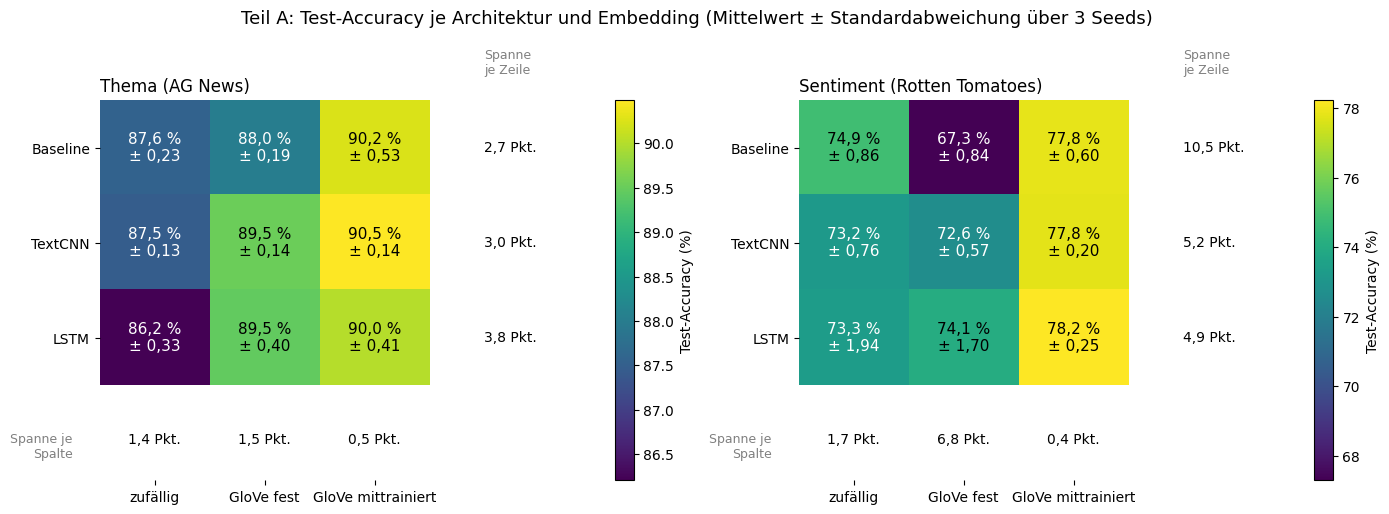

Abbildung gespeichert: RQ2_Heatmaps.png


In [44]:
import matplotlib.pyplot as plt


def heatmap_values(summary, task):
    """3x3 arrays (architecture x embedding) of mean and std, in percent."""
    s = summary[summary["task"] == task].set_index(["arch", "variante"])
    mean = np.array([[s.loc[(a, e), "acc_mean"] * 100 for e in EMBEDDINGS] for a in ARCHITECTURES])
    std = np.array([[s.loc[(a, e), "acc_std"] * 100 for e in EMBEDDINGS] for a in ARCHITECTURES])
    return mean, std


figure, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for axis, task in zip(axes, DATA):
    mean, std = heatmap_values(summary_a, task)
    image = axis.imshow(mean, cmap="viridis", aspect="auto")
    for i in range(3):
        for j in range(3):
            bright = mean[i, j] > mean.min() + 0.6 * (mean.max() - mean.min())
            axis.text(j, i, f"{mean[i, j]:.1f} %\n± {std[i, j]:.2f}".replace(".", ","),
                      ha="center", va="center", fontsize=11, color="black" if bright else "white")
    row_span = mean.max(axis=1) - mean.min(axis=1)        # embedding changes, architecture fixed
    col_span = mean.max(axis=0) - mean.min(axis=0)        # architecture changes, embedding fixed
    for i in range(3):
        axis.text(3.0, i, f"{row_span[i]:.1f}".replace(".", ",") + " Pkt.", ha="left", va="center", fontsize=10)
    for j in range(3):
        axis.text(j, 3.0, f"{col_span[j]:.1f}".replace(".", ",") + " Pkt.", ha="center", va="top", fontsize=10)
    axis.text(3.0, -0.75, "Spanne\nje Zeile", ha="left", va="bottom", fontsize=9, color="gray")
    axis.text(-0.75, 3.0, "Spanne je\nSpalte", ha="right", va="top", fontsize=9, color="gray")
    axis.set_xticks(range(3), [EMB_LABELS[e] for e in EMBEDDINGS])
    axis.set_yticks(range(3), [ARCH_LABELS[a] for a in ARCHITECTURES])
    axis.set_xlim(-0.5, 3.6)
    axis.set_ylim(3.5, -0.5)
    for side in ["top", "right", "bottom", "left"]:
        axis.spines[side].set_visible(False)
    axis.set_title(TASK_LABELS[task], loc="left", fontsize=12)
    figure.colorbar(image, ax=axis, fraction=0.04, pad=0.12, label="Test-Accuracy (%)")

figure.suptitle("Teil A: Test-Accuracy je Architektur und Embedding (Mittelwert ± Standardabweichung über 3 Seeds)",
                fontsize=13)
figure.tight_layout()
figure.savefig("RQ2_Heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(figure)
print("Abbildung gespeichert: RQ2_Heatmaps.png")

## A.8 Bewegt die Architektur oder das Embedding mehr?

Die Aufgabe vergleicht die **Spannweite je Spalte** (Architektur wechselt, Embedding fest) mit der **Spannweite je Zeile** (Embedding wechselt, Architektur fest). Die Zelle stellt beide nebeneinander und gibt je Aufgabe das Ergebnis in einem Satz aus.

Zur Einordnung zeigen wir auch die **mittlere Standardabweichung über die Seeds**: Eine Spannweite, die kaum größer ist als die Streuung über die Seeds, ist kein belastbarer Unterschied.

In [45]:
span_rows = []
for task in DATA:
    mean, std = heatmap_values(summary_a, task)
    row_span = mean.max(axis=1) - mean.min(axis=1)
    col_span = mean.max(axis=0) - mean.min(axis=0)
    for i, arch in enumerate(ARCHITECTURES):
        span_rows.append({"Aufgabe": task, "Richtung": "Zeile: Embedding wechselt",
                          "fest": ARCH_LABELS[arch], "Spannweite (Pkt.)": row_span[i]})
    for j, variante in enumerate(EMBEDDINGS):
        span_rows.append({"Aufgabe": task, "Richtung": "Spalte: Architektur wechselt",
                          "fest": EMB_LABELS[variante], "Spannweite (Pkt.)": col_span[j]})
    print(f"{TASK_LABELS[task]}: Spannweite je Zeile (Embedding wechselt) im Mittel {row_span.mean():.1f} Pkt., "
          f"je Spalte (Architektur wechselt) im Mittel {col_span.mean():.1f} Pkt., "
          f"Streuung über die Seeds im Mittel {std.mean():.1f} Pkt. "
          f"-> stärker bewegt: {'das Embedding' if row_span.mean() > col_span.mean() else 'die Architektur'}")

display(pd.DataFrame(span_rows).style.format({"Spannweite (Pkt.)": "{:.1f}"}).hide(axis="index"))

Thema (AG News): Spannweite je Zeile (Embedding wechselt) im Mittel 3.2 Pkt., je Spalte (Architektur wechselt) im Mittel 1.1 Pkt., Streuung über die Seeds im Mittel 0.3 Pkt. -> stärker bewegt: das Embedding
Sentiment (Rotten Tomatoes): Spannweite je Zeile (Embedding wechselt) im Mittel 6.9 Pkt., je Spalte (Architektur wechselt) im Mittel 3.0 Pkt., Streuung über die Seeds im Mittel 0.9 Pkt. -> stärker bewegt: das Embedding


Aufgabe,Richtung,fest,Spannweite (Pkt.)
thema,Zeile: Embedding wechselt,Baseline,2.7
thema,Zeile: Embedding wechselt,TextCNN,3.0
thema,Zeile: Embedding wechselt,LSTM,3.8
thema,Spalte: Architektur wechselt,zufällig,1.4
thema,Spalte: Architektur wechselt,GloVe fest,1.5
thema,Spalte: Architektur wechselt,GloVe mittrainiert,0.5
sentiment,Zeile: Embedding wechselt,Baseline,10.5
sentiment,Zeile: Embedding wechselt,TextCNN,5.2
sentiment,Zeile: Embedding wechselt,LSTM,4.9
sentiment,Spalte: Architektur wechselt,zufällig,1.7


# Teil B: Wie belastbar ist die Rangfolge?

## B.1 Welche Spalte nehmen wir?

Jede Spalte einer Heatmap ist eine Kombination aus Aufgabe und Embedding, zusammen sechs. Die Aufgabe verlangt die Spalte, in der der Abstand zwischen der **besten und der zweitbesten Architektur am kleinsten** ist, weil dort der Seed am ehesten über die Rangfolge entscheidet.

Die Zelle berechnet diesen Abstand für alle sechs Spalten aus den Mittelwerten von Teil A und wählt die Spalte mit dem kleinsten Abstand. Die Wahl beruht damit nur auf den Zahlen aus Teil A.

In [46]:
column_rows = []
for task in DATA:
    s = summary_a[summary_a["task"] == task]
    for variante in EMBEDDINGS:
        col = s[s["variante"] == variante].sort_values("acc_mean", ascending=False)
        column_rows.append({
            "task": task, "variante": variante,
            "Platz 1": ARCH_LABELS[col.iloc[0]["arch"]], "Platz 2": ARCH_LABELS[col.iloc[1]["arch"]],
            "Platz 3": ARCH_LABELS[col.iloc[2]["arch"]],
            "gap": (col.iloc[0]["acc_mean"] - col.iloc[1]["acc_mean"]) * 100,
        })

columns = pd.DataFrame(column_rows).sort_values("gap").reset_index(drop=True)
B_TASK, B_VARIANTE = columns.loc[0, "task"], columns.loc[0, "variante"]

display(columns.rename(columns={"task": "Aufgabe", "variante": "Embedding", "gap": "Abstand Platz 1 zu 2 (Pkt.)"})
        .style.format({"Abstand Platz 1 zu 2 (Pkt.)": "{:.2f}"}).hide(axis="index"))
print(f"Gewählte Spalte für Teil B: Aufgabe '{B_TASK}', Embedding '{EMB_LABELS[B_VARIANTE]}' "
      f"(Abstand Platz 1 zu Platz 2: {columns.loc[0, 'gap']:.2f} Punkte)")

Aufgabe,Embedding,Platz 1,Platz 2,Platz 3,Abstand Platz 1 zu 2 (Pkt.)
thema,glove_fest,TextCNN,LSTM,Baseline,0.06
thema,zufaellig,Baseline,TextCNN,LSTM,0.08
thema,glove_mittrainiert,TextCNN,Baseline,LSTM,0.24
sentiment,glove_mittrainiert,LSTM,Baseline,TextCNN,0.41
sentiment,glove_fest,LSTM,TextCNN,Baseline,1.44
sentiment,zufaellig,Baseline,LSTM,TextCNN,1.53


Gewählte Spalte für Teil B: Aufgabe 'thema', Embedding 'GloVe fest' (Abstand Platz 1 zu Platz 2: 0.06 Punkte)


## B.2 Seeds 4 bis 10 nachlegen

In der gewählten Spalte trainieren wir alle drei Architekturen mit den Seeds **4 bis 10**. Zusammen mit den Seeds 1 bis 3 aus Teil A hat dann jede Architektur **10 Seeds**. Das sind **21 zusätzliche Läufe**, mit denselben Einstellungen wie in Teil A. Auch diese Läufe kommen ins Ergebnisschema.

In [47]:
SEEDS_B_EXTRA = list(range(4, 11))
SEEDS_B = SEEDS_A + SEEDS_B_EXTRA       # seeds 1 to 10

start_b = time.time()
for arch in ARCHITECTURES:
    accs = [run_once(B_TASK, arch, B_VARIANTE, seed, LR[arch])["test_acc"] for seed in SEEDS_B_EXTRA]
    print(f"{ARCH_LABELS[arch]:9s} Seeds 4 bis 10: {[f'{a:.1%}' for a in accs]}")
print(f"\nTeil B fertig: {len(SEEDS_B_EXTRA) * 3} Läufe in {(time.time() - start_b) / 60:.1f} Minuten")

total_seconds = sum(r["seconds"] for r in run_info)
print(f"Reine Trainingszeit aller gespeicherten Läufe: {total_seconds / 60:.1f} Minuten ({len(run_info)} Läufe)")

Baseline  Seeds 4 bis 10: ['87.6%', '88.6%', '88.4%', '87.9%', '87.1%', '88.4%', '88.3%']
TextCNN   Seeds 4 bis 10: ['89.1%', '89.8%', '89.5%', '89.5%', '89.0%', '89.5%', '89.2%']
LSTM      Seeds 4 bis 10: ['89.6%', '90.1%', '89.6%', '89.3%', '89.8%', '89.8%', '89.7%']

Teil B fertig: 21 Läufe in 7.8 Minuten
Reine Trainingszeit aller gespeicherten Läufe: 20.7 Minuten (75 Läufe)


## B.3 Alle Auswahlen von k Seeds

Jetzt hat jede Architektur **10 Test-Accuracies**. Für k = 1 bis 9 gehen wir mit `subset_means` (Abschnitt 6) **alle möglichen Auswahlen** von k Seeds durch: 10, 45, 120, 210, 252, 210, 120, 45 und 10 Auswahlen. Für jede Auswahl gibt es einen Mittelwert. Daraus bilden wir je k und Modell:

- den **Durchschnitt** über alle Auswahlen (die Linie),
- das **Band** vom 5. bis zum 95. Perzentil: Dort liegen 90 % aller möglichen Mittelwerte. Ein einzelnes Experiment mit k Seeds landet irgendwo in diesem Band.

**Die Regel der Aufgabe:** Die Rangfolge zweier Modelle ist klar, sobald sich ihre Bänder **nicht mehr überlappen**. Die Zelle sucht für jedes Modellpaar das kleinste k, ab dem das gilt. Neues Training braucht das nicht, es ist eine Auswertung der vorhandenen 10 Läufe.

**Wichtig beim Lesen:** Die Auswahlen stammen alle aus denselben 10 Läufen. Bei k = 9 unterscheiden sich zwei Auswahlen nur in einem Seed, deshalb werden die Bänder zum Ende hin automatisch sehr schmal. Ein „klar ab k = 9“ heißt also: Mit fast allen unserer 10 Seeds ist die Reihenfolge eindeutig, aber nicht, dass 9 neue Seeds sicher dieselbe Reihenfolge liefern würden. Aussagekräftig sind vor allem die kleinen k, besonders **k = 3** (so viele Seeds hatte Teil A).

Die Abbildung wird als `RQ2_TeilB.png` gespeichert.

,Seed 1,Seed 2,Seed 3,Seed 4,Seed 5,Seed 6,Seed 7,Seed 8,Seed 9,Seed 10,Mittel,Std
Baseline,87.88,88.24,87.93,87.61,88.61,88.43,87.95,87.08,88.39,88.34,88.05,0.46
TextCNN,89.47,89.41,89.68,89.14,89.78,89.49,89.49,89.00,89.51,89.17,89.41,0.24
LSTM,89.14,89.34,89.91,89.55,90.11,89.55,89.26,89.78,89.80,89.72,89.62,0.30


Modellpaar,Abstand bei 10 Seeds (Pkt.),vorne bei 10 Seeds,Rangfolge klar ab k
Baseline gegen TextCNN,1.37,TextCNN,1
Baseline gegen LSTM,1.57,LSTM,1
TextCNN gegen LSTM,0.20,LSTM,7


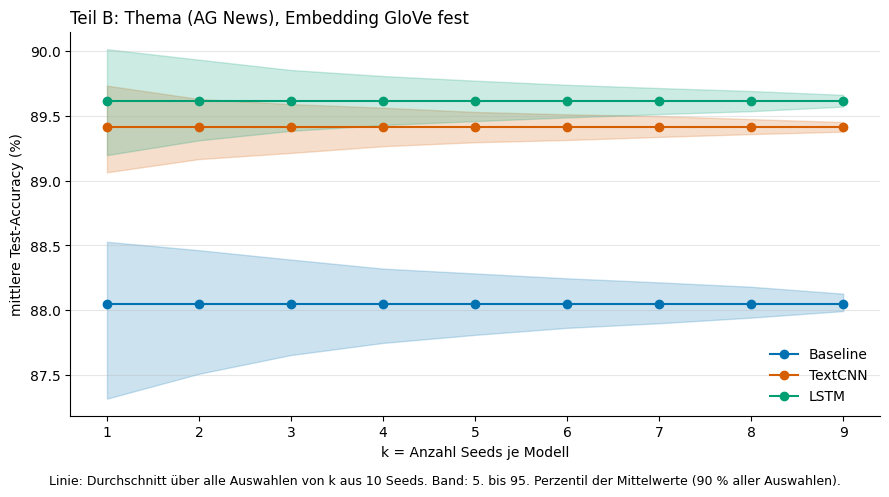

Abbildung gespeichert: RQ2_TeilB.png


In [48]:
from itertools import combinations as pairs_of

df_b = results_frame()
df_b = df_b[(df_b["task"] == B_TASK) & (df_b["variante"] == B_VARIANTE) & (df_b["split"] == "test")
            & (df_b["metrik"] == "accuracy") & (df_b["seed"].isin(SEEDS_B))]
ten = {arch: df_b[df_b["arch"] == arch].sort_values("seed")["wert"].to_numpy() * 100 for arch in ARCHITECTURES}
assert all(len(v) == 10 for v in ten.values()), "Every architecture needs exactly 10 seeds"

K_VALUES = range(1, 10)
band = {}                                # (arch, k) -> (mean, lower 5 %, upper 95 %)
for arch in ARCHITECTURES:
    for k in K_VALUES:
        means = subset_means(ten[arch], k)
        band[(arch, k)] = (means.mean(), np.percentile(means, 5), np.percentile(means, 95))

# The 10 seeds per model
display(pd.DataFrame({ARCH_LABELS[a]: ten[a] for a in ARCHITECTURES}, index=[f"Seed {s}" for s in SEEDS_B])
        .T.assign(Mittel=lambda t: t.mean(axis=1), Std=lambda t: t.iloc[:, :10].std(axis=1))
        .style.format("{:.2f}"))

# Smallest k from which the bands of two models no longer overlap (and stay apart up to k = 9)
pair_rows = []
for a, b in pairs_of(ARCHITECTURES, 2):
    separated = [band[(a, k)][1] > band[(b, k)][2] or band[(b, k)][1] > band[(a, k)][2] for k in K_VALUES]
    smallest = next((k for k in K_VALUES if all(separated[k - 1:])), None)
    front = a if ten[a].mean() > ten[b].mean() else b
    pair_rows.append({
        "Modellpaar": f"{ARCH_LABELS[a]} gegen {ARCH_LABELS[b]}",
        "Abstand bei 10 Seeds (Pkt.)": abs(ten[a].mean() - ten[b].mean()),
        "vorne bei 10 Seeds": ARCH_LABELS[front],
        "Rangfolge klar ab k": "gilt bei 10 Seeds nicht" if smallest is None else str(smallest),
    })
pair_table = pd.DataFrame(pair_rows)
display(pair_table.style.format({"Abstand bei 10 Seeds (Pkt.)": "{:.2f}"}).hide(axis="index"))

# Figure: mean accuracy against k with band
colors = {"baseline": "#0072B2", "textcnn": "#D55E00", "lstm": "#009E73"}
figure, axis = plt.subplots(figsize=(9, 4.8))
for arch in ARCHITECTURES:
    ks = list(K_VALUES)
    axis.plot(ks, [band[(arch, k)][0] for k in ks], marker="o", color=colors[arch], label=ARCH_LABELS[arch])
    axis.fill_between(ks, [band[(arch, k)][1] for k in ks], [band[(arch, k)][2] for k in ks],
                      color=colors[arch], alpha=0.2)
axis.set_xticks(list(K_VALUES))
axis.set_xlabel("k = Anzahl Seeds je Modell")
axis.set_ylabel("mittlere Test-Accuracy (%)")
axis.set_title(f"Teil B: {TASK_LABELS[B_TASK]}, Embedding {EMB_LABELS[B_VARIANTE]}", loc="left")
axis.grid(axis="y", alpha=0.3)
for side in ["top", "right"]:
    axis.spines[side].set_visible(False)
axis.legend(frameon=False)
figure.text(0.5, -0.02, "Linie: Durchschnitt über alle Auswahlen von k aus 10 Seeds. "
            "Band: 5. bis 95. Perzentil der Mittelwerte (90 % aller Auswahlen).", ha="center", fontsize=9)
figure.tight_layout()
figure.savefig("RQ2_TeilB.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(figure)
print("Abbildung gespeichert: RQ2_TeilB.png")

## B.4 Wie oft stimmt die Rangfolge bei k Seeds?

Die Bänder zeigen, wie stark der Mittelwert **eines** Modells schwankt. Die Leitfrage zielt aber auf die **Rangfolge aller drei**. Deshalb zählen wir zusätzlich: Wenn jedes Modell eine eigene, zufällige Auswahl von k Seeds bekommt, wie oft kommt **dieselbe Rangfolge** heraus wie mit allen 10 Seeds? Wir gehen dafür **alle Kombinationen** der Auswahlen der drei Modelle durch (bei k = 3 sind das 120 × 120 × 120 ≈ 1,7 Millionen).

Diese Zahl beantwortet direkt: *Wie belastbar ist die Rangfolge bei 3 Seeds?*

In [49]:
order_10 = sorted(ARCHITECTURES, key=lambda a: -ten[a].mean())        # ranking with all 10 seeds
print("Rangfolge mit 10 Seeds:", " > ".join(ARCH_LABELS[a] for a in order_10))

agreement_rows = []
for k in K_VALUES:
    m1, m2, m3 = (subset_means(ten[a], k).astype(np.float32) for a in order_10)
    # broadcast: every selection of model 1 with every selection of model 2 and 3
    same = (m1[:, None, None] > m2[None, :, None]) & (m2[None, :, None] > m3[None, None, :])
    first_two = (m1[:, None] > m2[None, :]).mean()
    agreement_rows.append({"k": k, "Kombinationen": same.size,
                           "dieselbe Rangfolge wie bei 10 Seeds": same.mean(),
                           f"{ARCH_LABELS[order_10[0]]} vor {ARCH_LABELS[order_10[1]]}": first_two})

agreement = pd.DataFrame(agreement_rows)
display(agreement.style.format({c: "{:.1%}" for c in agreement.columns if c not in ("k", "Kombinationen")}
                               | {"Kombinationen": "{:,}"}).hide(axis="index"))

Rangfolge mit 10 Seeds: LSTM > TextCNN > Baseline


k,Kombinationen,dieselbe Rangfolge wie bei 10 Seeds,LSTM vor TextCNN
1,"1,000",71.0%,71.0%
2,"91,125",78.1%,78.1%
3,"1,728,000",85.3%,85.3%
4,"9,261,000",90.6%,90.6%
5,"16,003,008",94.9%,94.9%
6,"9,261,000",97.9%,97.9%
7,"1,728,000",99.6%,99.6%
8,"91,125",100.0%,100.0%
9,"1,000",100.0%,100.0%


# Zusatzbefunde (über die Aufgabe hinaus)

## Z.1 Lohnt sich der Aufwand? Laufzeit und Parameter gegen Accuracy

Eine der vorgeschlagenen Fragen: *Wie verhalten sich Laufzeit und Parameterzahl zur Accuracy? Gibt es eine Konfiguration, die sich nicht lohnt?* Dafür brauchen wir **kein neues Training**, die Werte stammen aus Teil A.

Die Abbildung zeigt je Aufgabe die mittlere Laufzeit (x-Achse, logarithmisch) gegen die mittlere Test-Accuracy (y-Achse). Die Form steht für die Architektur, die Farbe für das Embedding.

Eine Konfiguration **lohnt sich nicht**, wenn es eine andere gibt, die **schneller und mindestens genauso genau** ist. Die Tabelle unter der Abbildung markiert jede Konfiguration mit „ja“ oder „nein“ und nennt bei „nein“ die schnellste bessere Alternative. Weil kleine Unterschiede in der Accuracy im Rauschen der Seeds liegen, zählen wir eine andere Konfiguration als „mindestens genauso genau“, wenn sie höchstens eine Standardabweichung (Mittel über die Seeds) schlechter ist.

Die Abbildung wird als `RQ2_Zusatz_Laufzeit.png` gespeichert.

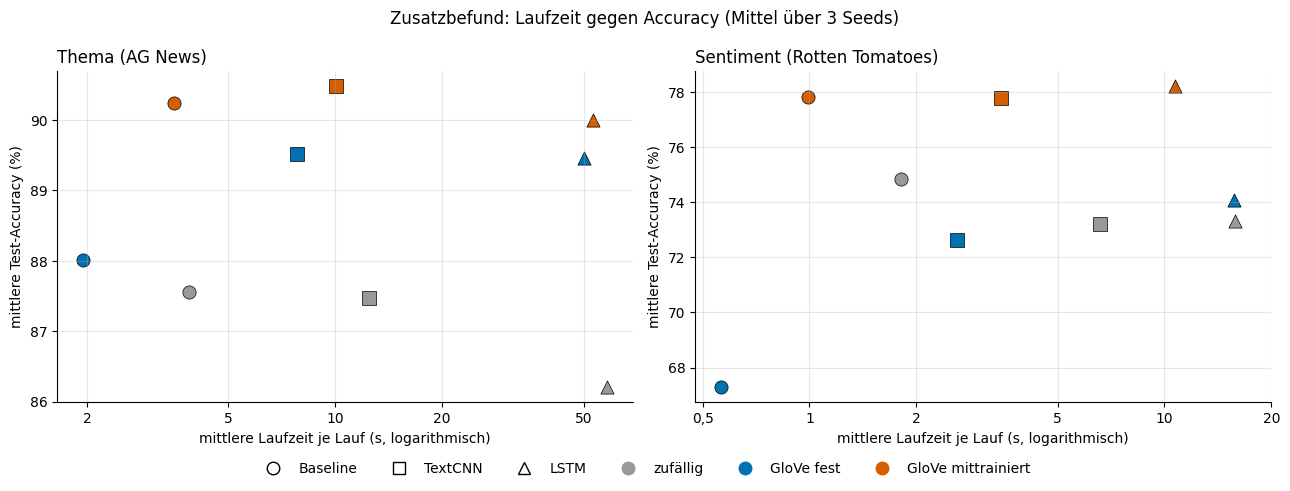

Aufgabe,Konfiguration,Accuracy (%),Laufzeit (s),lohnt sich?,schneller und mind. gleich gut
thema,"Baseline, GloVe fest",88.0,2.0,ja,
thema,"Baseline, GloVe mittrainiert",90.2,3.5,ja,
thema,"Baseline, zufällig",87.6,3.9,nein,Baseline GloVe fest
thema,"TextCNN, GloVe fest",89.5,7.8,nein,Baseline GloVe mittrainiert
thema,"TextCNN, GloVe mittrainiert",90.5,10.0,nein,Baseline GloVe mittrainiert
thema,"TextCNN, zufällig",87.5,12.5,nein,Baseline GloVe fest
thema,"LSTM, GloVe fest",89.5,50.3,nein,Baseline GloVe mittrainiert
thema,"LSTM, GloVe mittrainiert",90.0,53.1,nein,Baseline GloVe mittrainiert
thema,"LSTM, zufällig",86.2,58.2,nein,Baseline GloVe fest
sentiment,"Baseline, GloVe fest",67.3,0.6,ja,


Thema (AG News): 2 von 9 Konfigurationen lohnen sich: Baseline, GloVe fest; Baseline, GloVe mittrainiert
Sentiment (Rotten Tomatoes): 2 von 9 Konfigurationen lohnen sich: Baseline, GloVe fest; Baseline, GloVe mittrainiert
Abbildung gespeichert: RQ2_Zusatz_Laufzeit.png


In [50]:
markers = {"baseline": "o", "textcnn": "s", "lstm": "^"}
emb_colors = {"zufaellig": "#999999", "glove_fest": "#0072B2", "glove_mittrainiert": "#D55E00"}

figure, axes = plt.subplots(1, 2, figsize=(13, 4.6))
dominated_rows = []
for axis, task in zip(axes, DATA):
    s = summary_a[summary_a["task"] == task].reset_index(drop=True)
    tolerance = s["acc_std"].mean() * 100
    for _, r in s.iterrows():
        axis.scatter(r["seconds"], r["acc_mean"] * 100, marker=markers[r["arch"]], s=90,
                     color=emb_colors[r["variante"]], edgecolors="black", linewidths=0.5)
    for _, r in s.iterrows():
        # dominated = another configuration is faster AND at most one seed-std worse
        better = s[(s["seconds"] < r["seconds"]) & (s["acc_mean"] * 100 >= r["acc_mean"] * 100 - tolerance)]
        dominated_rows.append({
            "Aufgabe": task, "Konfiguration": f"{ARCH_LABELS[r['arch']]}, {EMB_LABELS[r['variante']]}",
            "Accuracy (%)": r["acc_mean"] * 100, "Laufzeit (s)": r["seconds"],
            "lohnt sich?": "ja" if better.empty else "nein",
            "schneller und mind. gleich gut": "" if better.empty else ", ".join(
                f"{ARCH_LABELS[b['arch']]} {EMB_LABELS[b['variante']]}"
                for _, b in better.sort_values("seconds").head(1).iterrows()),
        })
    axis.set_xscale("log")
    ticks = [t for t in [0.5, 1, 2, 5, 10, 20, 50, 100] if s["seconds"].min() / 1.5 <= t <= s["seconds"].max() * 1.5]
    axis.set_xticks(ticks, [str(t).replace(".", ",") for t in ticks])
    axis.minorticks_off()
    axis.set_xlabel("mittlere Laufzeit je Lauf (s, logarithmisch)")
    axis.set_ylabel("mittlere Test-Accuracy (%)")
    axis.set_title(TASK_LABELS[task], loc="left")
    axis.grid(alpha=0.3)
    for side in ["top", "right"]:
        axis.spines[side].set_visible(False)

from matplotlib.lines import Line2D
handles = [Line2D([], [], marker=markers[a], ls="none", color="white", markeredgecolor="black", markersize=9,
                  label=ARCH_LABELS[a]) for a in ARCHITECTURES]
handles += [Line2D([], [], marker="o", ls="none", color=emb_colors[e], markersize=9, label=EMB_LABELS[e])
            for e in EMBEDDINGS]
figure.legend(handles=handles, loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.06))
figure.suptitle("Zusatzbefund: Laufzeit gegen Accuracy (Mittel über 3 Seeds)", fontsize=12)
figure.tight_layout()
figure.savefig("RQ2_Zusatz_Laufzeit.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(figure)

worth = pd.DataFrame(dominated_rows).sort_values(["Aufgabe", "Laufzeit (s)"], ascending=[False, True])
display(worth.style.format({"Accuracy (%)": "{:.1f}", "Laufzeit (s)": "{:.1f}"}).hide(axis="index"))
for task in DATA:
    keep = worth[(worth["Aufgabe"] == task) & (worth["lohnt sich?"] == "ja")]["Konfiguration"].tolist()
    print(f"{TASK_LABELS[task]}: {len(keep)} von 9 Konfigurationen lohnen sich: {'; '.join(keep)}")
print("Abbildung gespeichert: RQ2_Zusatz_Laufzeit.png")

## Z.2 Wie viele Seeds wären nötig?

Eine zweite vorgeschlagene Frage: *Wie viele Seeds wären nötig, damit die engste Rangfolge stabil wird?* Wenn sich zwei Bänder in B.3 auch bei k = 9 noch überlappen, können wir das nur **schätzen**.

**Die Schätzung:** Der Mittelwert aus k Seeds schwankt ungefähr mit der Standardabweichung der Seeds geteilt durch die Wurzel aus k. Das 90-%-Band reicht dann etwa 1,645 solche Einheiten nach oben und unten. Zwei Bänder trennen sich, wenn der Abstand der Mittelwerte größer ist als die beiden halben Bandbreiten zusammen:

`Abstand > 1,645 × (Std_A + Std_B) / Wurzel(k)`  →  `k > (1,645 × (Std_A + Std_B) / Abstand)²`

Das ist eine **Näherung** mit der Normalverteilung und mit der Standardabweichung aus nur 10 Läufen. Sie zeigt die Größenordnung, keinen exakten Wert.

In [51]:
needed_rows = []
for a, b in pairs_of(ARCHITECTURES, 2):
    gap = abs(ten[a].mean() - ten[b].mean())
    std_sum = ten[a].std(ddof=1) + ten[b].std(ddof=1)
    k_needed = int(np.ceil((1.645 * std_sum / gap) ** 2)) if gap > 0 else None
    needed_rows.append({"Modellpaar": f"{ARCH_LABELS[a]} gegen {ARCH_LABELS[b]}",
                        "Abstand (Pkt.)": gap, "Std A + Std B (Pkt.)": std_sum,
                        "geschätzt nötige Seeds je Modell": k_needed})
display(pd.DataFrame(needed_rows).style.format({"Abstand (Pkt.)": "{:.2f}", "Std A + Std B (Pkt.)": "{:.2f}"})
        .hide(axis="index"))

Modellpaar,Abstand (Pkt.),Std A + Std B (Pkt.),geschätzt nötige Seeds je Modell
Baseline gegen TextCNN,1.37,0.70,1
Baseline gegen LSTM,1.57,0.76,1
TextCNN gegen LSTM,0.20,0.55,20


# Gesamtfazit

Die Zelle fasst die wichtigsten Zahlen aus diesem Lauf zusammen. Sie werden direkt aus den Ergebnissen berechnet, damit Text und Zahlen nach einem neuen Lauf zusammenpassen. Die Deutung steht in der Markdown-Zelle darunter.

In [52]:
from IPython.display import Markdown

lines = []
for task in DATA:
    mean, std = heatmap_values(summary_a, task)
    row_span = mean.max(axis=1) - mean.min(axis=1)
    col_span = mean.max(axis=0) - mean.min(axis=0)
    s = summary_a[summary_a["task"] == task].sort_values("acc_mean", ascending=False)
    best, worst = s.iloc[0], s.iloc[-1]
    lines.append(
        f"- **{TASK_LABELS[task]}:** Embedding wechseln bewegt im Mittel **{row_span.mean():.1f} Pkt.**, "
        f"Architektur wechseln **{col_span.mean():.1f} Pkt.** "
        f"Beste Konfiguration: {ARCH_LABELS[best['arch']]} mit {EMB_LABELS[best['variante']]} ({best['acc_mean']:.1%}), "
        f"schwächste: {ARCH_LABELS[worst['arch']]} mit {EMB_LABELS[worst['variante']]} ({worst['acc_mean']:.1%})."
    )
k3 = agreement.set_index("k").loc[3, "dieselbe Rangfolge wie bei 10 Seeds"]
lines.append(
    f"- **Teil B ({TASK_LABELS[B_TASK]}, {EMB_LABELS[B_VARIANTE]}):** Rangfolge mit 10 Seeds "
    f"{' > '.join(ARCH_LABELS[a] for a in order_10)}, Abstände {pair_table['Abstand bei 10 Seeds (Pkt.)'].min():.2f} "
    f"bis {pair_table['Abstand bei 10 Seeds (Pkt.)'].max():.2f} Pkt. Mit k = 3 Seeds kommt dieselbe Rangfolge in "
    f"**{k3:.0%}** der Kombinationen heraus (reiner Zufall bei drei Modellen: 17 %)."
)
for _, r in pair_table.iterrows():
    k_text = r["Rangfolge klar ab k"]
    lines.append(f"  - {r['Modellpaar']}: " + ("Bänder überlappen auch bei k = 9 noch" if not k_text.isdigit()
                                                else f"Bänder getrennt ab k = {k_text}"))
display(Markdown("\n".join(lines)))

- **Thema (AG News):** Embedding wechseln bewegt im Mittel **3.2 Pkt.**, Architektur wechseln **1.1 Pkt.** Beste Konfiguration: TextCNN mit GloVe mittrainiert (90.5%), schwächste: LSTM mit zufällig (86.2%).
- **Sentiment (Rotten Tomatoes):** Embedding wechseln bewegt im Mittel **6.9 Pkt.**, Architektur wechseln **3.0 Pkt.** Beste Konfiguration: LSTM mit GloVe mittrainiert (78.2%), schwächste: Baseline mit GloVe fest (67.3%).
- **Teil B (Thema (AG News), GloVe fest):** Rangfolge mit 10 Seeds LSTM > TextCNN > Baseline, Abstände 0.20 bis 1.57 Pkt. Mit k = 3 Seeds kommt dieselbe Rangfolge in **85%** der Kombinationen heraus (reiner Zufall bei drei Modellen: 17 %).
  - Baseline gegen TextCNN: Bänder getrennt ab k = 1
  - Baseline gegen LSTM: Bänder getrennt ab k = 1
  - TextCNN gegen LSTM: Bänder getrennt ab k = 7

## Deutung

**1. Das Embedding bewegt die Accuracy deutlich stärker als die Architektur.** Wechselt bei fester Architektur das Embedding, ändert sich die Accuracy im Mittel um 3,2 Punkte (Thema) bzw. 6,9 Punkte (Sentiment). Wechselt bei festem Embedding die Architektur, sind es nur 1,1 bzw. 3,0 Punkte. Beide Werte liegen klar über der Streuung über die Seeds (im Mittel 0,3 bzw. 0,9 Punkte). Mit mittrainiertem GloVe liegen alle drei Architekturen fast gleichauf (Thema 90,0 bis 90,5 %, Sentiment 77,8 bis 78,2 %). Das passt zu unserer Erwartung.

**2. Ob festes GloVe hilft, hängt von Aufgabe und Architektur ab.** Bei Thema hilft festes GloVe gegenüber zufälligen Vektoren, beim LSTM am meisten (+3,3 Punkte), bei der Baseline kaum (+0,5). GloVe wurde auf Nachrichten- und Wikipedia-Texten gelernt und passt damit gut zu AG News. Bei Sentiment fällt die Baseline mit festem GloVe auf 67,3 %, 7,6 Punkte unter „zufällig“: Ein Mittelwert aus festen Vektoren kann „good“ und „bad“ kaum trennen, weil beide Wörter in ähnlichen Kontexten vorkommen. TextCNN und LSTM gleichen das mit ihren eigenen Gewichten aus (72,6 bzw. 74,1 %). Erst wenn die Vektoren mittrainiert werden, lernen sie das Sentiment mit.

**3. Die Architektur zählt nur unter bestimmten Bedingungen.** Groß ist die Spannweite zwischen den Architekturen nur bei Sentiment mit festem GloVe (6,8 Punkte), sonst liegt sie bei 0,4 bis 1,7 Punkten. Unsere Erwartung, dass TextCNN und LSTM bei Sentiment klar vor der Baseline liegen, hat sich **nicht** bestätigt: Mit trainierbaren Embeddings ist die einfache Baseline gleich gut (mittrainiert) oder sogar vorne (zufällig).

**4. Die Reihenfolge der beiden führenden Modelle änderte sich zwischen drei und zehn Seeds.** Bei AG News mit festem GloVe lag das TextCNN nach drei Seeds um 0,06 Prozentpunkte vor dem LSTM. Mit zehn Seeds liegt das LSTM um 0,20 Prozentpunkte vorn. Im Resampling trennt sich das Band der Baseline ab k = 1 von den Bändern der beiden anderen Modelle. Für TextCNN und LSTM trennen sich die Bänder ab k = 7. Bei k = 3 ergibt sich in 85,3 % der Kombinationen dieselbe Rangfolge wie mit allen zehn Seeds. Die Seed-Auswahl aus Teil A gehört zu den Kombinationen mit abweichender Reihenfolge. Die Normalverteilungsnäherung aus Z.2 liefert für TextCNN und LSTM eine grobe Schätzung von rund 20 Seeds. Die Bänder aus Teil B werden mit steigendem k schmaler, weil sich die Auswahlen aus denselben zehn Läufen immer stärker überschneiden.

**5. Laufzeit und Accuracy.** Bei AG News erreicht die Baseline mit mittrainiertem GloVe 90,25 % Test-Accuracy. Das LSTM erreicht mit demselben Embedding 90,00 % und benötigt deutlich mehr Trainingszeit. Die gemessenen Laufzeiten je Konfiguration stehen in A.6 und Z.1.

**Grenzen.** Für jede Architektur haben wir die Lernrate aus zwei Kandidaten gewählt. Bei AG News haben wir mit 20.000 Trainingstexten gearbeitet. Die Rangfolge haben wir für eine Kombination aus Aufgabe und Embedding vertieft untersucht. Die Schätzung der nötigen Seed-Anzahl beruht auf einer Normalverteilungsnäherung.

**Laufzeit.** B.2 gibt die Trainingszeit der 75 Hauptläufe aus. Die gemessene Gesamtlaufzeit bis zum CSV-Export steht in Abschnitt 7.

## 7. Export

Schreibt alle gesammelten Ergebnisse als CSV neben das Notebook. Die Zelle prüft vorher, ob jede Zeile genau die sieben Spalten hat. Die CSV wird mit abgegeben.

In [53]:
import csv

RESULTS_FILE = "rq2_results.csv"

bad_rows = [i for i, row in enumerate(results) if set(row) != set(RESULT_COLUMNS)]
if bad_rows:
    raise ValueError(f"Rows {bad_rows[:5]} do not match the result schema {RESULT_COLUMNS}")

with open(RESULTS_FILE, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=RESULT_COLUMNS)
    writer.writeheader()
    writer.writerows(results)

print(f"{len(results)} rows written to {RESULTS_FILE}")

300 rows written to rq2_results.csv


## 8. Abgabecheckliste

- [ ] Teamnamen oben eingetragen
- [ ] **Restart & Run All** läuft ohne Fehler durch
- [ ] `set_seed` wird zu Beginn jedes Laufs aufgerufen, Teil A hat mindestens 3 Seeds je Konfiguration, Teil B 10 Seeds je Architektur
- [ ] Alle 18 Konfigurationen (3 Architekturen × 3 Embedding-Varianten × 2 Aufgaben) sind gemessen
- [ ] Pro Architektur dieselben Hyperparameter über alle Embeddings und Aufgaben, Auswahl nur auf Validation, nie auf dem Testset
- [ ] `N_TRAIN_THEMA` und `N_VAL_THEMA` begründet und danach nicht mehr geändert, alle anderen festen Werte unverändert
- [ ] Parameterzahl jeder Architektur ausgegeben (`count_params`) und im Bericht genannt
- [ ] Teil B: Aufgabe und Embedding anhand von Teil A begründet gewählt
- [ ] Teil B: für jedes Modell Durchschnitt und Band über k = 1 bis 9, kleinstes k je Modellpaar im Bericht genannt
- [ ] `rq2_results.csv` erzeugt, Schema eingehalten
- [ ] Jede Abbildung im Bericht lässt sich aus diesem Notebook erzeugen
- [ ] Abgabe: Bericht (PDF), Notebook, CSV, Beitragsnachweis, KI-Hinweis